# Two-pulse semiclassical LLG dynamics and spectra

This notebook simulates a canted two-sublattice antiferromagnet driven by two THz pulses. Both pulses are polarized along the crystallographic $a$ axis and both are on. Their delay is initially set to $\tau=10$ ps. We calculate the undamped ($\alpha=0$) LLG dynamics and one-dimensional FFT spectra of the resulting magnetization.

In [14]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from two_spin_dynamics.llg import run_llg, run_llg_reduced
from two_spin_dynamics.pulses import d2gdt2_pulse, single_thz_pulse, two_thz_pulses
from two_spin_dynamics.plotting import (
    LEGEND_STYLES,
    PLOT_CONFIG,
    PLOT_STYLES,
    plot_field_components,
    plot_two_pulses,
    plot_fft_spectrum,
    plot_magnetization_dynamics,
    plot_time_series,
)
from two_spin_dynamics.spectral_analysis import rfft_spectrum
from two_spin_dynamics.spin_hamiltonian import canted_afm_ground_state, effective_fields_no_external

plt.rcParams.update(PLOT_CONFIG)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Hamiltonian parameters setup

In [2]:
# Energies are in meV; spin length is dimensionless.
temperature = 300.0  # K; here K_a > K_c, so the canted-AFM ground state has L || a.
ham_params = {
    'Stot': 5.0 / 2.0,
    'nn': 6,
    'Jex': 4.6,
    'Dvec': np.array([0.0, 0.1066, 0.0]),  # D || b
    'Kvec': np.array([0.00905, 0.0, 0.9847 / (temperature + 62.38) + 0.00265]),
}

S1_eq, S2_eq, beta0 = canted_afm_ground_state(ham_params)
M_eq = S1_eq + S2_eq

print(f'K_a = {ham_params["Kvec"][0]:.6f} meV, K_c = {ham_params["Kvec"][2]:.6f} meV')
print(f'Canting angle beta_0 = {np.degrees(beta0):.5f} deg')
print(f'Equilibrium net magnetization M_eq = {M_eq}')

K_a = 0.009050 meV, K_c = 0.005367 meV
Canting angle beta_0 = 0.66368 deg
Equilibrium net magnetization M_eq = [0.         0.         0.05791539]


## Pulse parameters setup: $H_A\parallel a$, $H_B\parallel a$

In [3]:
tau_delay = 10.0  # ps: centre-to-centre delay between pulses A and B
sigma = 0.5       # ps
h_peak = 0.15     # T

pulse_params = {
    'A': {
        'shape_params': {'t0': 0.0, 'sigma': sigma, 'h_peak': h_peak},
        'polarization': np.array([1.0, 0.0, 0.0]),
        'state': 'on',
    },
    'B': {
        'shape_params': {'t0': tau_delay, 'sigma': sigma, 'h_peak': h_peak},
        'polarization': np.array([1.0, 0.0, 0.0]),
        'state': 'on',
    },
}

start_time, end_time = -5.0, 30.0  # ps; long post-pulse window improves FFT resolution
time = np.linspace(start_time, end_time, 2**10)

H_A = single_thz_pulse(time, pulse_params['A'], d2gdt2_pulse)
H_B = single_thz_pulse(time, pulse_params['B'], d2gdt2_pulse)
H_total = two_thz_pulses(time, pulse_params, d2gdt2_pulse)

print(f'Pulse delay tau = {tau_delay:.1f} ps')
print(f'Output spacing dt = {time[1] - time[0]:.4f} ps')
print(f'FFT bin spacing over the full window = {1 / (time.size * (time[1] - time[0])):.4f} THz')

Pulse delay tau = 10.0 ps
Output spacing dt = 0.0342 ps
FFT bin spacing over the full window = 0.0285 THz


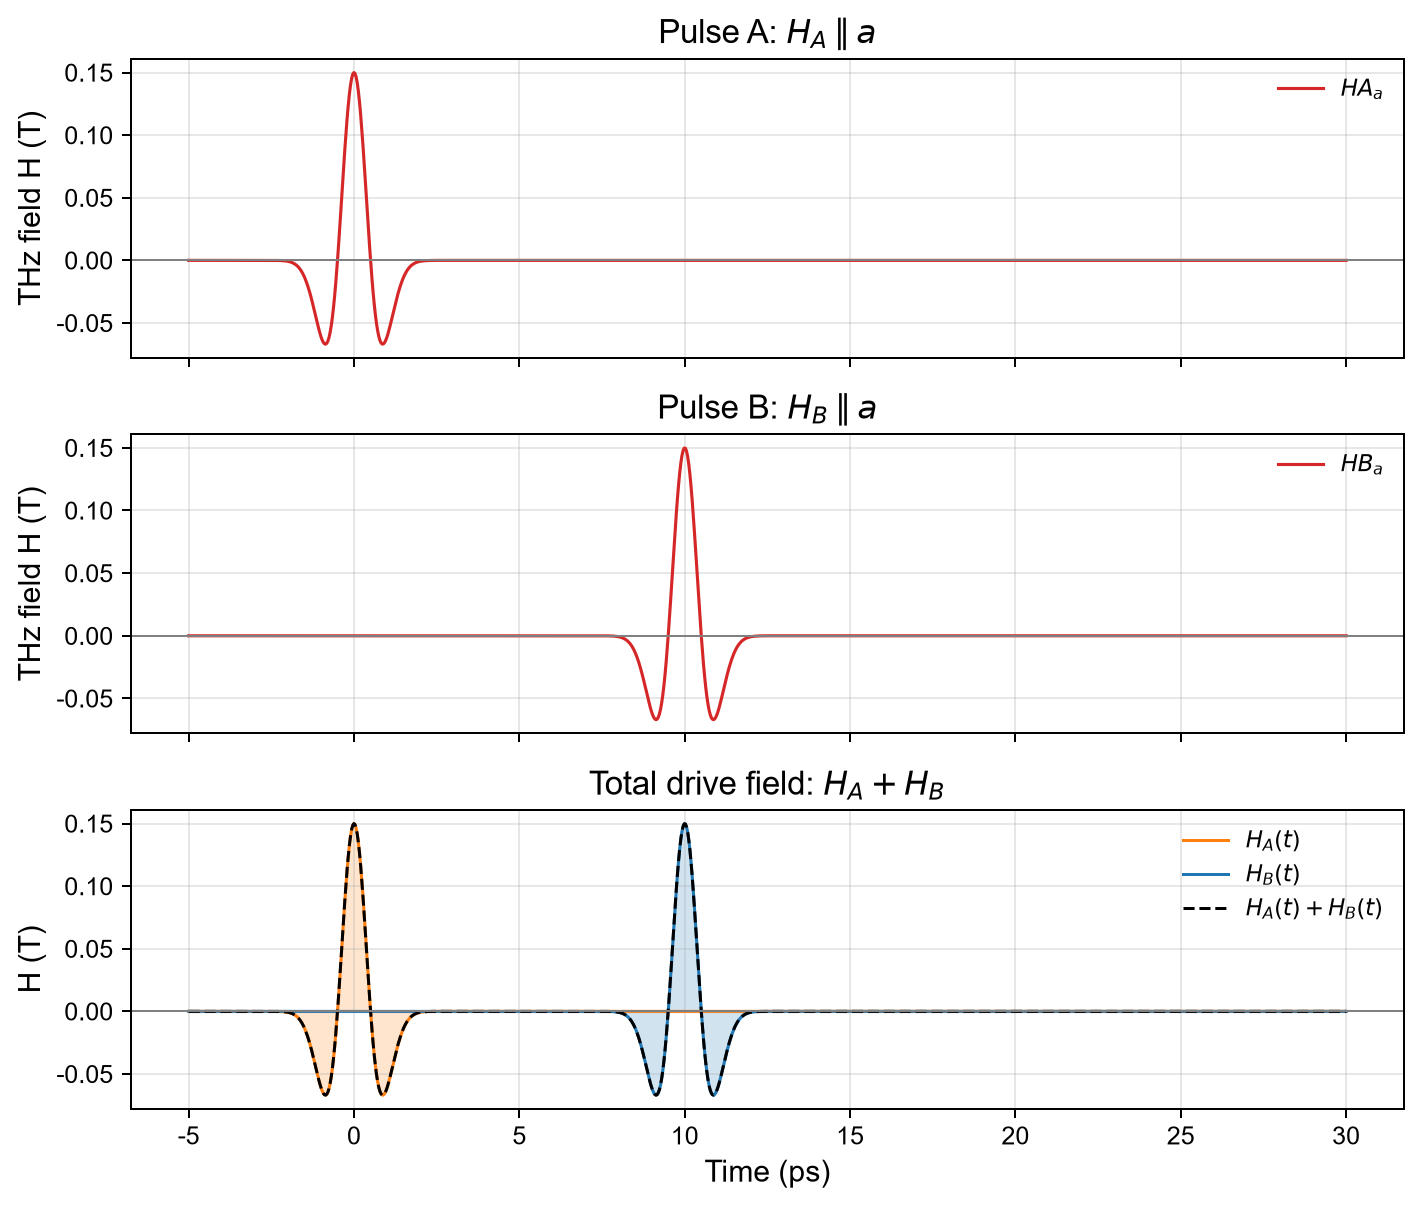

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6.8), dpi=180, sharex=True)
plot_field_components(axes[0], time, H_A, title=r'Pulse A: $H_A \parallel a$', xlabel=None, base_label="HA")
plot_field_components(axes[1], time, H_B, title=r'Pulse B: $H_B \parallel a$', xlabel=None, base_label="HB")
# plot_field_components(axes[2], time, H_total, title=r'Total drive field: $H_A + H_B$')
plot_two_pulses(time, H_A[:,0], H_B[:,0], ax=axes[2], title=r'Total drive field: $H_A + H_B$')
fig.tight_layout()

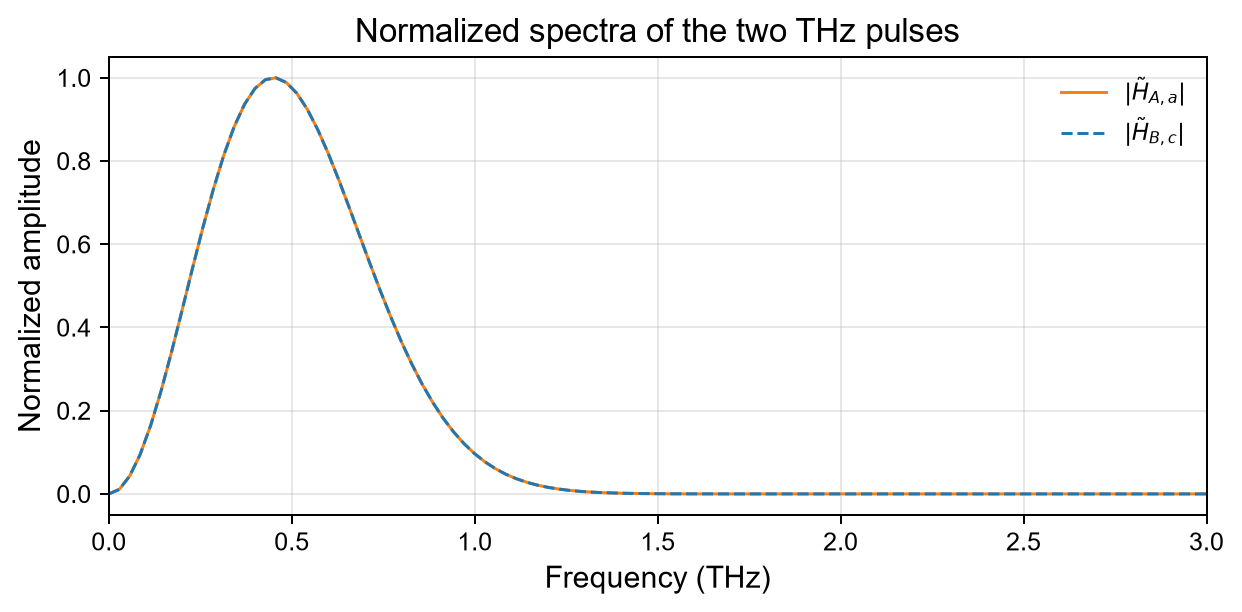

In [5]:
# Spectra of the independently polarized pulse components.
f_pulse, _, A_a = rfft_spectrum(time, H_A[:, 0], normalize=True, remove_mean=True)
_, _, B_c = rfft_spectrum(time, H_B[:, 0], normalize=True, remove_mean=True)

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=180)
plot_styles_pulse_b = PLOT_STYLES['pulse_b'].copy()
plot_styles_pulse_b['linestyle'] = '--'
plot_time_series(
    ax, f_pulse,
    {r'$|\tilde H_{A,a}|$': A_a, r'$|\tilde H_{B,c}|$': B_c},
    styles=[PLOT_STYLES['pulse_a'], plot_styles_pulse_b],
    title='Normalized spectra of the two THz pulses',
    xlabel='Frequency (THz)', ylabel='Normalized amplitude', xlim=(0, 3),
    legend_config=LEGEND_STYLES['compact'],
)
fig.tight_layout()

## LLG simulation: $\alpha=0$, both THz pulses on

### Six Components Simulation

In [6]:
alpha = 0.0
result = run_llg(
    time, S1_eq, S2_eq, ham_params, alpha, pulse_params, d2gdt2_pulse,
    method='DOP853', rtol=1e-9, atol=1e-11, max_step=0.01,
)

S1, S2, M = result['S1'], result['S2'], result['M']
spin_length_error_1 = np.max(np.abs(np.linalg.norm(S1, axis=1) - ham_params['Stot']))
spin_length_error_2 = np.max(np.abs(np.linalg.norm(S2, axis=1) - ham_params['Stot']))
print(f'Max |S1| conservation error: {spin_length_error_1:.3e}')
print(f'Max |S2| conservation error: {spin_length_error_2:.3e}')

Max |S1| conservation error: 9.770e-15
Max |S2| conservation error: 8.438e-15


Maximum |M(t) - M(0)|: 2.432e-03


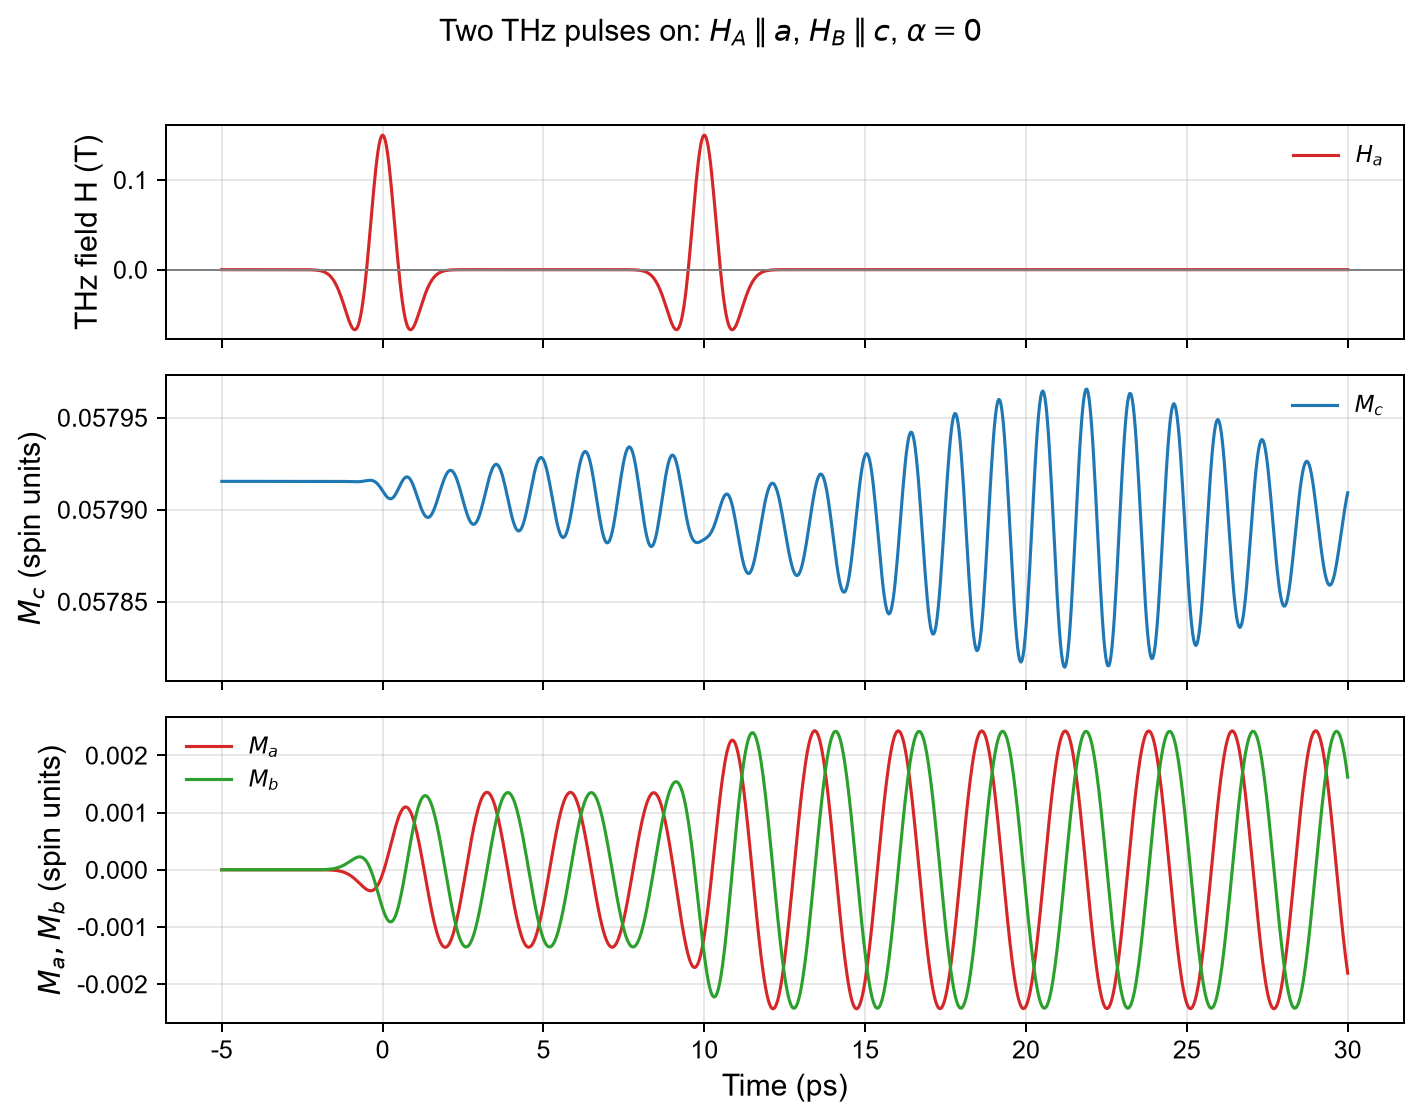

In [7]:
fig, axes = plot_magnetization_dynamics(
    time, M, pulse=H_total,
    title=r'Two THz pulses on: $H_A\parallel a$, $H_B\parallel c$, $\alpha=0$',
    legend_config=LEGEND_STYLES['compact'],
)

print(f'Maximum |M(t) - M(0)|: {np.max(np.abs(M - M[0])):.3e}')

### Four Components Simulation
the result is expected to be the same but slower ( why ? )

In [18]:
def update_S1S2(sol, Stot):
    S1b, S1c, S2b, S2c = np.asarray(sol, dtype=float)
    S1a_sq = Stot**2 - S1b**2 - S1c**2
    S2a_sq = Stot**2 - S2b**2 - S2c**2

    tolerance = 1e-12 * Stot**2

    if S1a_sq < -tolerance:
        raise ValueError("The S1a exceed the Stot")
    # if S2a_sq < -tolerance:
    #     raise ValueError("The S2a exceed the Stot")
    if S2a_sq < -tolerance:
        raise ValueError("The S2a exceed the Stot")

    S1a =  np.sqrt(max(S1a_sq, 0.0)) # S1a is positive
    S2a = -np.sqrt(max(S2a_sq, 0.0)) # S2a is negative
    S1 = np.array([S1a, S1b, S1c])
    S2 = np.array([S2a, S2b, S2c])
    
    return S1, S2

def LLG_S1S2_dynamics(t, sol, Ham_params, alpha, pulse_params, pulse_func):
    """
        Four-component LLG RHS compatible with scipy.integrate.solve_ivp.
    """
    S1, S2 = update_S1S2(sol, Ham_params["Stot"]) # dimensionless

    # internal fields
    H1_internal, H2_internal = effective_fields_no_external(S1, S2, Ham_params)
    H1_internal = H1_internal / 0.6582119569 # unit is ps^-1
    H2_internal = H2_internal / 0.6582119569 # unit is ps^-1

    # external field
    H_external = two_thz_pulses(t, pulse_params, pulse_func) # unit is Tesla
    H_external = H_external * 0.176086 # unit is ps^-1

    def llg(S, H_eff):
        precession = np.cross(H_eff, S)
        damping = np.cross(S, precession) / Ham_params["Stot"]
        return 1 / (1 + alpha**2) * (precession + alpha * damping)

    dS1_dt = llg(S1, H1_internal + H_external)
    dS2_dt = llg(S2, H2_internal + H_external)

    # Only the independent b and c components are integrated.
    return np.array([dS1_dt[1], dS1_dt[2], dS2_dt[1], dS2_dt[2]])

In [19]:
from scipy.integrate import solve_ivp

In [23]:
alpha = 0.0

sol0 = np.array([S1_eq[1], S1_eq[2], S2_eq[1], S2_eq[2]])

sol_on = solve_ivp(
    LLG_S1S2_dynamics,
    (time[0], time[-1]),
    sol0,
    t_eval=time,
    args=(ham_params, alpha, pulse_params, d2gdt2_pulse),
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.01,
)

S1 = np.empty((time.size, 3))
S2 = np.empty((time.size, 3))
for index, state in enumerate(sol_on.y.T):
    S1[index], S2[index] = update_S1S2(state, ham_params["Stot"])

M = (S1 + S2)

In [ ]:
# alpha = 0.01
# result = run_llg_reduced(
#     time, S1_eq, S2_eq, ham_params, alpha, pulse_params, d2gdt2_pulse,
#     method='DOP853', rtol=1e-9, atol=1e-11, max_step=0.01,
# )

# S1, S2, M = result['S1'], result['S2'], result['M']
# spin_length_error_1 = np.max(np.abs(np.linalg.norm(S1, axis=1) - ham_params['Stot']))
# spin_length_error_2 = np.max(np.abs(np.linalg.norm(S2, axis=1) - ham_params['Stot']))
# print(f'Max |S1| conservation error: {spin_length_error_1:.3e}')
# print(f'Max |S2| conservation error: {spin_length_error_2:.3e}')

Max |S1| conservation error: 0.000e+00
Max |S2| conservation error: 0.000e+00


Maximum |M(t) - M(0)|: 2.432e-03


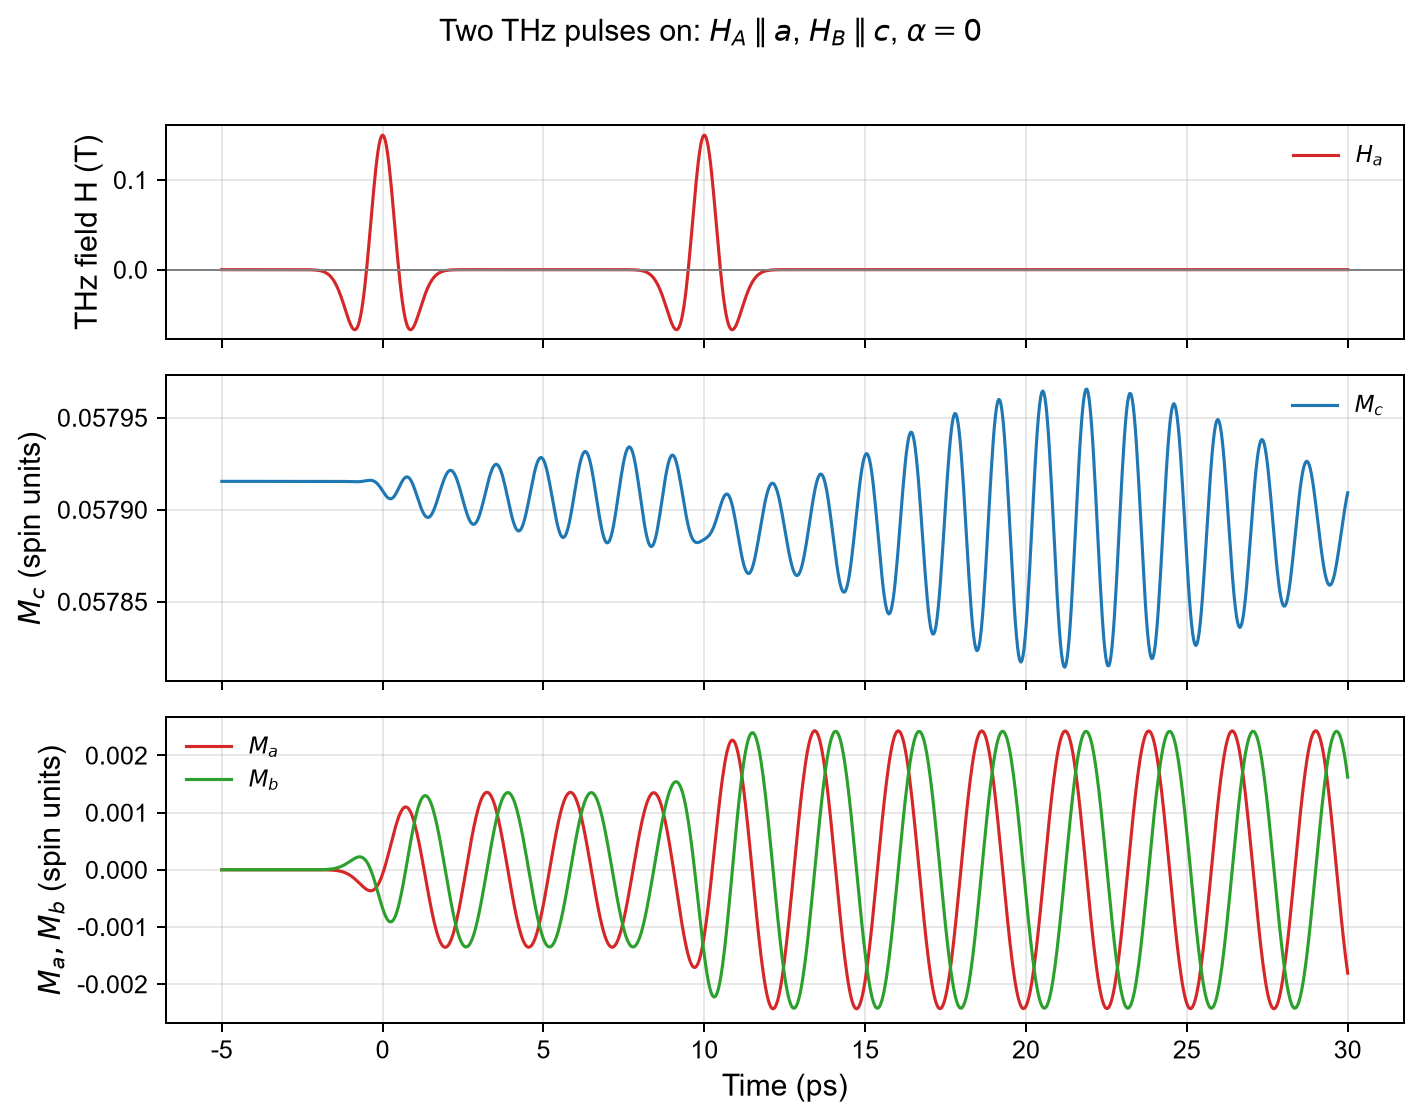

In [25]:
fig, axes = plot_magnetization_dynamics(
    time, M, pulse=H_total,
    title=r'Two THz pulses on: $H_A\parallel a$, $H_B\parallel c$, $\alpha=0$',
    legend_config=LEGEND_STYLES['compact'],
)

print(f'Maximum |M(t) - M(0)|: {np.max(np.abs(M - M[0])):.3e}')

## Magnetization dynamics and FFT spectra

Post-pulse FFT duration: 18.00 ps
Post-pulse frequency spacing: 0.0555 THz
Largest non-DC FFT peak: 0.3882 THz


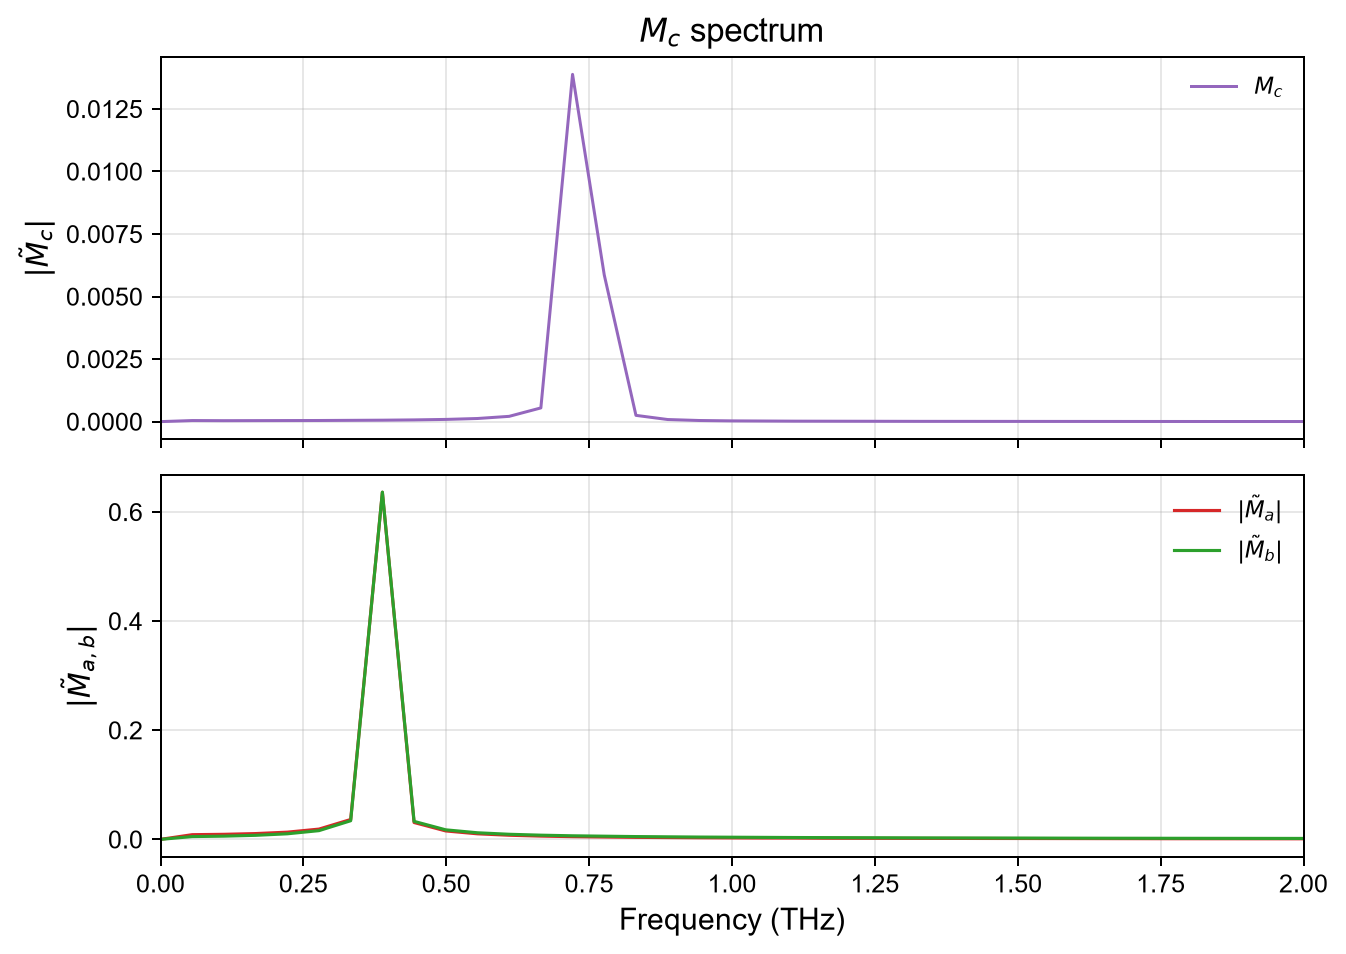

In [24]:
# Analyse only the freely evolving response after pulse B has vanished.
t_fft_start = tau_delay + 4 * sigma
fft_mask = time >= t_fft_start
frequency, spectrum, amplitude = rfft_spectrum(
    time[fft_mask], M[fft_mask], normalize=False, remove_mean=True
)
print(f'Post-pulse FFT duration: {time[fft_mask][-1] - time[fft_mask][0]:.2f} ps')
print(f'Post-pulse frequency spacing: {frequency[1] - frequency[0]:.4f} THz')

fig, (ax_c, ax_ab) = plt.subplots(2, 1, figsize=(7.5, 5.4), dpi=180, sharex=True)
plot_fft_spectrum(
    frequency, amplitude[:, 2], ax=ax_c, title=r'$M_c$ spectrum', label=r'$M_c$',
    xlabel=None, ylabel=r'$|\tilde M_c|$', xlim=(0, 2),
)
plot_time_series(
    ax_ab, frequency,
    {r'$|\tilde M_a|$': amplitude[:, 0], r'$|\tilde M_b|$': amplitude[:, 1]},
    styles=[PLOT_STYLES['component_a'], PLOT_STYLES['component_b']],
    xlabel='Frequency (THz)', ylabel=r'$|\tilde M_{a,b}|$', xlim=(0, 2),
    legend_config=LEGEND_STYLES['compact'],
)
fig.tight_layout()

peak_index = np.unravel_index(np.argmax(amplitude[1:]), amplitude[1:].shape)
print(f'Largest non-DC FFT peak: {frequency[peak_index[0] + 1]:.4f} THz')